# County Covariates: Manufacturing Exposure and Real Wages

Extends the Part 3 county profile with BLS QCEW employment data and re-tests the economic regression.

**Inputs:** `data/raw/bls_qcew/qcew_county_summary.csv` (from `bls_qcew_pull.py`), `data/raw/fred/CPIAUCSL.csv`, `data/processed/county_economic_profile.csv` (from notebook 04)

**New variables:**
- `mfg_share_2016` — manufacturing share of private employment, pre-Trump baseline
- `mfg_share_chg_2016_2024` — change in that share (pp)
- `mfg_emp_pct_chg_2016_2024` — % change in manufacturing jobs
- `private_emp_pct_chg_2020_2024` — % change in all private jobs over the Biden term
- `real_pay_pct_chg_2020_2024` — % change in CPI-deflated average private pay over the Biden term

Then: the notebook 04 WLS is re-fit with **HC3 robust standard errors** (the original residuals had kurtosis of 28, so the nonrobust p-values were not reliable), extended with the new variables, and run separately on the turnout and share components from notebook 03.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

RAW_DIR     = Path('../data/raw')
PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')
for d in [PROC_DIR, FIGURES_DIR, TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

YEARS = [2012, 2016, 2020, 2024]

## 1. Load QCEW and deflate pay to 2024 dollars

In [2]:
qcew = pd.read_csv(RAW_DIR / 'bls_qcew' / 'qcew_county_summary.csv')

cpi = pd.read_csv(RAW_DIR / 'fred' / 'CPIAUCSL.csv', index_col=0, parse_dates=True)
cpi.columns = ['cpi']
cpi_annual = cpi.groupby(cpi.index.year)['cpi'].mean()

for yr in YEARS:
    qcew[f'real_pay_{yr}'] = qcew[f'private_avg_pay_{yr}'] * cpi_annual[2024] / cpi_annual[yr]

print(f'QCEW counties: {len(qcew):,}')
print('CPI deflators (to 2024$):', {yr: round(cpi_annual[2024] / cpi_annual[yr], 3) for yr in YEARS})
qcew[[f'real_pay_{yr}' for yr in YEARS] + [f'mfg_share_{yr}' for yr in YEARS]].describe().round(3)

QCEW counties: 3,236
CPI deflators (to 2024$): {2012: 1.366, 2016: 1.307, 2020: 1.212, 2024: 1.0}


,real_pay_2012,real_pay_2016,real_pay_2020,real_pay_2024,mfg_share_2012,mfg_share_2016,mfg_share_2020,mfg_share_2024
count,3208.000,3207.000,3207.000,3215.000,2899.000,2893.000,2884.000,2840.000
mean,47910.640,49611.766,53693.611,53100.903,0.159,0.159,0.161,0.156
std,12744.174,12622.531,14219.291,13509.375,0.117,0.120,0.120,0.117
min,18880.418,16628.242,17197.573,18514.000,0.000,0.000,0.000,0.000
25%,40372.641,42418.877,45806.671,45535.000,0.070,0.067,0.068,0.066
50%,45633.143,47432.706,51490.923,51018.000,0.135,0.132,0.136,0.130
75%,52626.877,54069.233,58451.874,57724.500,0.225,0.224,0.226,0.220
max,152717.142,159544.594,205311.707,205596.000,0.745,0.881,0.907,0.835


## 2. Suppression

BLS withholds a county-sector cell when one or two employers dominate it. Those are exactly the small single-plant counties where a closure matters most, so dropping them is not neutral. Counties with no manufacturing establishments at all are already coded as zero by `bls_qcew_pull.py`, so a missing value here means suppressed, not absent. Strategy: fill a suppressed year from the nearest available year (2016 from 2012, then 2020; 2024 from 2020) and carry a flag.

In [3]:
qcew['mfg_suppressed'] = qcew[['mfg_share_2016', 'mfg_share_2024']].isna().any(axis=1)

mfg16 = qcew['mfg_share_2016'].fillna(qcew['mfg_share_2012']).fillna(qcew['mfg_share_2020'])
mfg24 = qcew['mfg_share_2024'].fillna(qcew['mfg_share_2020'])

print(f'Suppressed in 2016 or 2024:        {qcew["mfg_suppressed"].sum():>5}  ({qcew["mfg_suppressed"].mean():.1%})')
print(f'Still missing after nearest-year fill: {mfg16.isna().sum():>5} (2016)   {mfg24.isna().sum():>5} (2024)')

# Suppressed counties are systematically smaller
print()
print(qcew.groupby('mfg_suppressed')['private_emp_2020'].median().rename('median private emp 2020'))

Suppressed in 2016 or 2024:          500  (15.5%)
Still missing after nearest-year fill:   203 (2016)     267 (2024)

mfg_suppressed
False    7965.0
True     1007.0
Name: median private emp 2020, dtype: float64


## 3. Change variables

In [4]:
cov = pd.DataFrame({
    'county_fips':                   qcew['county_fips'],
    'mfg_share_2016':                mfg16,
    'mfg_share_chg_2016_2024':       (mfg24 - mfg16) * 100,
    'mfg_emp_pct_chg_2016_2024':     (qcew['mfg_emp_2024'] / qcew['mfg_emp_2016'] - 1) * 100,
    'private_emp_pct_chg_2020_2024': (qcew['private_emp_2024'] / qcew['private_emp_2020'] - 1) * 100,
    'real_pay_2020':                 qcew['real_pay_2020'],
    'real_pay_pct_chg_2020_2024':    (qcew['real_pay_2024'] / qcew['real_pay_2020'] - 1) * 100,
    'mfg_suppressed':                qcew['mfg_suppressed'],
})
cov.describe().round(2)

,county_fips,mfg_share_2016,mfg_share_chg_2016_2024,mfg_emp_pct_chg_2016_2024,private_emp_pct_chg_2020_2024,real_pay_2020,real_pay_pct_chg_2020_2024
count,3236.00,3033.00,2923.00,2706.00,3195.00,3207.00,3195.00
mean,31363.67,0.16,-0.33,inf,9.02,53693.61,-0.56
std,16383.34,0.12,3.80,NaN,13.41,14219.29,7.84
min,1001.00,0.00,-28.32,-85.07,-59.42,17197.57,-53.78
25%,19018.50,0.06,-1.71,-9.98,2.80,45806.67,-4.26
50%,30018.00,0.13,-0.10,3.04,7.96,51490.92,-1.12
75%,46107.50,0.22,1.16,19.27,13.59,58451.87,2.35
max,78030.00,0.88,53.55,inf,194.06,205311.71,136.27


## 4. Merge onto the autopsy counties and save

In [5]:
prof = pd.read_csv(PROC_DIR / 'county_economic_profile.csv')
turnout = pd.read_csv(PROC_DIR / 'county_decomposition.csv')[['county_fips', 'total_votes_2020', 'total_votes_2024']]
prof = prof.merge(turnout, on='county_fips', how='left')
prof['log_income'] = np.log(prof['med_income'])

df = prof.merge(cov, on='county_fips', how='left')

print(f'Autopsy counties:              {len(prof):,}')
print(f'Matched to QCEW:               {df["real_pay_2020"].notna().sum():,}')
print(f'With mfg_share_2016 (filled):  {df["mfg_share_2016"].notna().sum():,}')
print(f'With real_pay_pct_chg:         {df["real_pay_pct_chg_2020_2024"].notna().sum():,}')

df.to_csv(PROC_DIR / 'county_covariates.csv', index=False)
print(f'\nSaved: data/processed/county_covariates.csv  ({len(df):,} rows, {df.shape[1]} cols)')

Autopsy counties:              3,110
Matched to QCEW:               3,097
With mfg_share_2016 (filled):  2,931
With real_pay_pct_chg:         3,085

Saved: data/processed/county_covariates.csv  (3,110 rows, 25 cols)


## 5. Does manufacturing exposure explain the 2020→2024 swing?

`swing_2024` here is the **margin** swing (Dem% − Rep%, 2020→2024) inherited from notebook 03 — the same DV notebook 04 used. All three models are fit on the same restricted sample (counties with complete QCEW data) so their coefficients are directly comparable; M0 will differ slightly from notebook 04's full-sample fit.

- **M0** — notebook 04 spec, nonrobust SEs
- **M1** — same spec, HC3 robust SEs
- **M2** — M1 + manufacturing exposure + Biden-term job and real-pay change, HC3

Standardized effects below use turnout-weighted SDs, matching the regression weights.

In [6]:
base_formula = 'swing_2024 ~ log_income + college_share + white_nocollege + unemp_rate + dem_share_2020'
ext_formula  = (base_formula + ' + mfg_share_2016 + mfg_share_chg_2016_2024'
                             + ' + private_emp_pct_chg_2020_2024 + real_pay_pct_chg_2020_2024')

ext_vars = ['mfg_share_2016', 'mfg_share_chg_2016_2024',
            'private_emp_pct_chg_2020_2024', 'real_pay_pct_chg_2020_2024']
reg = df.dropna(subset=ext_vars).copy()
print(f'Regression sample: {len(reg):,} counties  ({reg["total_votes_2020"].sum() / df["total_votes_2020"].sum():.1%} of 2020 votes)\n')

m0 = smf.wls(base_formula, data=reg, weights=reg['total_votes_2020']).fit()
m1 = smf.wls(base_formula, data=reg, weights=reg['total_votes_2020']).fit(cov_type='HC3')
m2 = smf.wls(ext_formula,  data=reg, weights=reg['total_votes_2020']).fit(cov_type='HC3')

def tidy(m, name):
    return pd.DataFrame({f'{name}_coef': m.params, f'{name}_se': m.bse, f'{name}_p': m.pvalues})

table = pd.concat([tidy(m0, 'M0'), tidy(m1, 'M1'), tidy(m2, 'M2')], axis=1).round(3)
print(f'R2   M0/M1: {m1.rsquared:.3f}   M2: {m2.rsquared:.3f}\n')
table

Regression sample: 2,817 counties  (97.7% of 2020 votes)

R2   M0/M1: 0.422   M2: 0.437



,M0_coef,M0_se,M0_p,M1_coef,M1_se,M1_p,M2_coef,M2_se,M2_p
Intercept,21.610,4.446,0.000,21.610,15.164,0.154,17.068,13.637,0.211
log_income,-3.415,0.398,0.000,-3.415,1.243,0.006,-2.891,1.132,0.011
college_share,20.635,1.121,0.000,20.635,2.990,0.000,21.447,3.037,0.000
white_nocollege,16.475,0.620,0.000,16.475,2.745,0.000,14.908,2.640,0.000
unemp_rate,-30.387,5.879,0.000,-30.387,15.585,0.051,-24.035,15.037,0.110
dem_share_2020,-1.575,0.730,0.031,-1.575,2.041,0.440,-2.614,1.988,0.188
mfg_share_2016,NaN,NaN,NaN,NaN,NaN,NaN,2.702,1.366,0.048
mfg_share_chg_2016_2024,NaN,NaN,NaN,NaN,NaN,NaN,-0.009,0.037,0.811
private_emp_pct_chg_2020_2024,NaN,NaN,NaN,NaN,NaN,NaN,-0.075,0.029,0.009
real_pay_pct_chg_2020_2024,NaN,NaN,NaN,NaN,NaN,NaN,0.059,0.052,0.257


In [7]:
def wtd_sd(x, w):
    mu = np.average(x, weights=w)
    return np.sqrt(np.average((x - mu) ** 2, weights=w))

sd = pd.Series({v: wtd_sd(reg[v], reg['total_votes_2020']) for v in m2.params.index.drop('Intercept')})
print('Effect of a +1 SD change on the 2020->2024 margin swing (pp), M2 with HC3 SEs:')
print(f'{"variable":32s} {"1 SD":>10s} {"effect":>8s} {"95% CI":>18s}')
for v in sd.index:
    b, se = m2.params[v], m2.bse[v]
    print(f'{v:32s} {sd[v]:>10.3f} {b * sd[v]:>+8.2f}   [{(b - 1.96 * se) * sd[v]:+.2f}, {(b + 1.96 * se) * sd[v]:+.2f}]')

Effect of a +1 SD change on the 2020->2024 margin swing (pp), M2 with HC3 SEs:
variable                               1 SD   effect             95% CI
log_income                            0.261    -0.75   [-1.33, -0.18]
college_share                         0.113    +2.43   [+1.75, +3.10]
white_nocollege                       0.177    +2.63   [+1.72, +3.55]
unemp_rate                            0.015    -0.36   [-0.79, +0.08]
dem_share_2020                        0.165    -0.43   [-1.08, +0.21]
mfg_share_2016                        0.079    +0.21   [+0.00, +0.43]
mfg_share_chg_2016_2024               1.963    -0.02   [-0.16, +0.13]
private_emp_pct_chg_2020_2024         6.706    -0.50   [-0.88, -0.13]
real_pay_pct_chg_2020_2024            4.374    +0.26   [-0.19, +0.70]


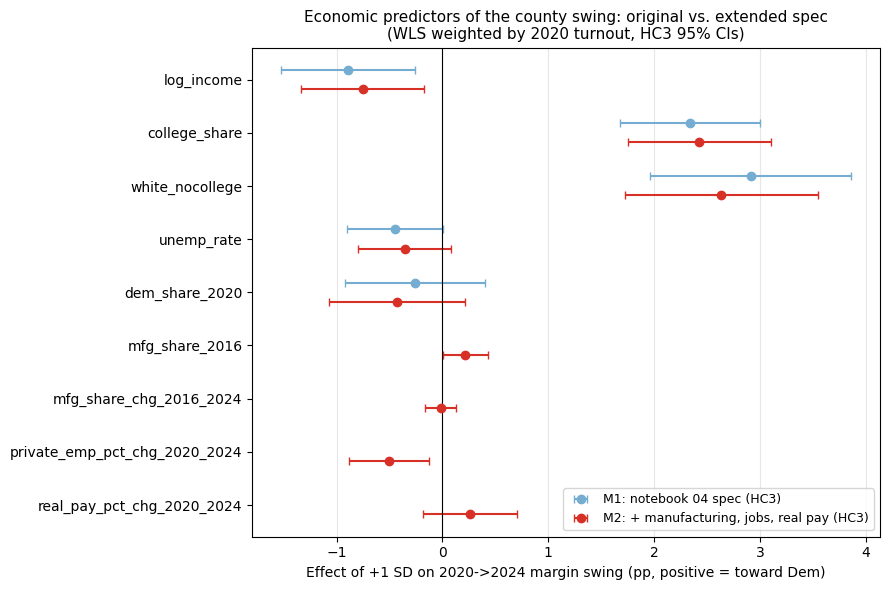

Saved: outputs/figures/covariates_coef_comparison.png


In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

order = list(m2.params.index.drop('Intercept'))
y = np.arange(len(order))[::-1]
for m, name, color, dy in [(m1, 'M1: notebook 04 spec (HC3)', '#74add1', 0.18),
                           (m2, 'M2: + manufacturing, jobs, real pay (HC3)', '#d73027', -0.18)]:
    for i, v in enumerate(order):
        if v not in m.params.index:
            continue
        eff = m.params[v] * sd[v]
        ci  = 1.96 * m.bse[v] * sd[v]
        ax.errorbar(eff, y[i] + dy, xerr=ci, fmt='o', color=color, capsize=3,
                    label=name if i == 0 else None)

ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel('Effect of +1 SD on 2020->2024 margin swing (pp, positive = toward Dem)')
ax.set_title('Economic predictors of the county swing: original vs. extended spec\n(WLS weighted by 2020 turnout, HC3 95% CIs)', fontsize=11)
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'covariates_coef_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/covariates_coef_comparison.png')

## 6. Which component do the economic variables explain?

Notebook 03 split each county's Democratic vote change into a turnout component and a share component, in raw votes. Normalizing both by 2020 turnout (votes per 100 2020 voters) puts every county on the same scale, and regressing each on the M2 spec shows whether the economic gradient runs through turnout, through share shift, or both.

In [9]:
reg['turnout_per100'] = reg['turnout_component'] / reg['total_votes_2020'] * 100
reg['share_per100']   = reg['share_component']   / reg['total_votes_2020'] * 100

rhs = ext_formula.split('~')[1]
m_turn  = smf.wls('turnout_per100 ~' + rhs, data=reg, weights=reg['total_votes_2020']).fit(cov_type='HC3')
m_share = smf.wls('share_per100 ~'   + rhs, data=reg, weights=reg['total_votes_2020']).fit(cov_type='HC3')

comp = pd.concat([tidy(m_turn, 'turnout'), tidy(m_share, 'share')], axis=1).round(3)
print(f'R2   turnout component: {m_turn.rsquared:.3f}   share component: {m_share.rsquared:.3f}')
print(f'Wtd mean, per 100 2020 voters:  turnout {np.average(reg["turnout_per100"], weights=reg["total_votes_2020"]):+.2f}'
      f'   share {np.average(reg["share_per100"], weights=reg["total_votes_2020"]):+.2f}\n')
comp

R2   turnout component: 0.510   share component: 0.445
Wtd mean, per 100 2020 voters:  turnout -1.58   share -2.35



,turnout_coef,turnout_se,turnout_p,share_coef,share_se,share_p
Intercept,18.627,8.156,0.022,11.913,6.284,0.058
log_income,-1.818,0.789,0.021,-1.693,0.514,0.001
college_share,9.030,2.700,0.001,10.065,1.384,0.000
white_nocollege,5.462,1.295,0.000,7.315,1.262,0.000
unemp_rate,-23.666,9.169,0.010,-15.459,7.261,0.033
dem_share_2020,-10.241,1.462,0.000,-1.455,0.939,0.121
mfg_share_2016,-0.826,1.161,0.477,1.004,0.679,0.140
mfg_share_chg_2016_2024,0.021,0.044,0.638,-0.009,0.018,0.614
private_emp_pct_chg_2020_2024,0.114,0.024,0.000,-0.034,0.012,0.006
real_pay_pct_chg_2020_2024,-0.002,0.029,0.954,0.021,0.024,0.384


In [10]:
print('Effect of +1 SD on Dem votes per 100 2020 voters (HC3):')
print(f'{"variable":32s} {"turnout":>9s} {"share":>9s}')
for v in sd.index:
    print(f'{v:32s} {m_turn.params[v] * sd[v]:>+9.2f} {m_share.params[v] * sd[v]:>+9.2f}')

Effect of +1 SD on Dem votes per 100 2020 voters (HC3):
variable                           turnout     share
log_income                           -0.47     -0.44
college_share                        +1.02     +1.14
white_nocollege                      +0.97     +1.29
unemp_rate                           -0.35     -0.23
dem_share_2020                       -1.69     -0.24
mfg_share_2016                       -0.07     +0.08
mfg_share_chg_2016_2024              +0.04     -0.02
private_emp_pct_chg_2020_2024        +0.76     -0.23
real_pay_pct_chg_2020_2024           -0.01     +0.09


## 7. Save tables

In [11]:
table.to_csv(TABLES_DIR / 'covariates_swing_regression.csv')
comp.to_csv(TABLES_DIR / 'covariates_component_regression.csv')
print('Saved:')
print('  outputs/tables/covariates_swing_regression.csv')
print('  outputs/tables/covariates_component_regression.csv')

Saved:
  outputs/tables/covariates_swing_regression.csv
  outputs/tables/covariates_component_regression.csv


## Next additions

Two more county-level covariates slot into section 3 once the files are downloaded (both are manual exports — see the technical appendix for steps):

- **CDC WONDER** overdose mortality, age-adjusted, 2018–2023 pooled → `data/raw/cdc/`
- **Medill / UNC news deserts** local outlet counts and closures → `data/raw/news_deserts/`

Both merge on `county_fips` the same way QCEW does.